In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)
print("TensorFlow Version:", tf.__version__)

print("All libraries imported successfully!")

TensorFlow Version: 2.21.0
All libraries imported successfully!


In [2]:

from google.colab import files

uploaded = files.upload()

Saving cleaned_customerchurn_dataset.csv to cleaned_customerchurn_dataset (1).csv


In [3]:
import pandas as pd
df = pd.read_csv("cleaned_customerchurn_dataset.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.shape

(180, 13)

In [5]:
df.head()

,Customer_ID,Age,Annual_Income,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score,Contract_Type,Payment_Method,Region,Plan_Type,Churn
0,CUST-1020,22.0,23800.0,11.0,62.96,7.0,20.4,5.0,Monthly,Bank Transfer,North,Standard,Yes
1,CUST-1043,35.0,69400.0,17.0,75.63,6.0,17.5,9.0,Monthly,Bank Transfer,South,Basic,Yes
2,CUST-1157,55.0,64700.0,49.0,92.85,3.0,21.6,1.0,Monthly,UPI,West,Basic,Yes
3,CUST-1112,36.0,80000.0,9.0,85.67,0.0,34.3,9.0,Monthly,UPI,South,Standard,Yes
4,CUST-1149,41.0,95700.0,51.0,60.77,1.0,23.7,9.0,Monthly,Debit Card,West,Premium,Yes


In [6]:
df.columns

Index(['Customer_ID', 'Age', 'Annual_Income', 'Tenure_Months',
       'Monthly_Charges', 'Support_Calls_Last_3M', 'Data_Usage_GB',
       'Satisfaction_Score', 'Contract_Type', 'Payment_Method', 'Region',
       'Plan_Type', 'Churn'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer_ID            180 non-null    object 
 1   Age                    180 non-null    float64
 2   Annual_Income          180 non-null    float64
 3   Tenure_Months          180 non-null    float64
 4   Monthly_Charges        180 non-null    float64
 5   Support_Calls_Last_3M  180 non-null    float64
 6   Data_Usage_GB          180 non-null    float64
 7   Satisfaction_Score     180 non-null    float64
 8   Contract_Type          180 non-null    object 
 9   Payment_Method         180 non-null    object 
 10  Region                 180 non-null    object 
 11  Plan_Type              180 non-null    object 
 12  Churn                  180 non-null    object 
dtypes: float64(7), object(6)
memory usage: 18.4+ KB


In [8]:
df.describe()

,Age,Annual_Income,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score
count,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000
mean,36.311111,65188.333333,38.627778,74.508333,3.055556,18.667222,5.761111
std,8.561502,21655.753296,19.372569,26.184246,1.584570,8.142247,2.811318
min,18.000000,8600.000000,1.000000,0.000000,0.000000,0.800000,1.000000
25%,31.000000,50800.000000,25.000000,58.035000,2.000000,13.150000,4.000000
50%,36.000000,64700.000000,38.000000,72.900000,3.000000,18.800000,6.000000
75%,41.000000,76650.000000,53.250000,88.750000,4.000000,24.125000,8.000000
max,63.000000,120900.000000,72.000000,151.180000,7.000000,44.000000,10.000000


In [9]:
df.isnull().sum()

,0
Customer_ID,0
Age,0
Annual_Income,0
Tenure_Months,0
Monthly_Charges,0
Support_Calls_Last_3M,0
Data_Usage_GB,0
Satisfaction_Score,0
Contract_Type,0
Payment_Method,0


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df['Churn'].value_counts()

,count
Churn,
Yes,94
No,86


In [12]:
X = df.drop(['Customer_ID', 'Churn'], axis=1)

y = df['Churn']

In [13]:
X = pd.get_dummies(X, drop_first=True, dtype=int)

le = LabelEncoder()

y = le.fit_transform(y)

In [14]:
X.head()

,Age,Annual_Income,Tenure_Months,Monthly_Charges,Support_Calls_Last_3M,Data_Usage_GB,Satisfaction_Score,Contract_Type_2 Year,Contract_Type_Monthly,Payment_Method_Credit Card,Payment_Method_Debit Card,Payment_Method_UPI,Payment_Method_Unknown,Region_North,Region_South,Region_West,Plan_Type_Premium,Plan_Type_Standard
0,22.0,23800.0,11.0,62.96,7.0,20.4,5.0,0,1,0,0,0,0,1,0,0,0,1
1,35.0,69400.0,17.0,75.63,6.0,17.5,9.0,0,1,0,0,0,0,0,1,0,0,0
2,55.0,64700.0,49.0,92.85,3.0,21.6,1.0,0,1,0,0,1,0,0,0,1,0,0
3,36.0,80000.0,9.0,85.67,0.0,34.3,9.0,0,1,0,0,1,0,0,1,0,0,1
4,41.0,95700.0,51.0,60.77,1.0,23.7,9.0,0,1,0,1,0,0,0,0,1,1,0


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [16]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [17]:
print("Training data shape:", X_train.shape)

print("Testing data shape:", X_test.shape)

print("Training target shape:", y_train.shape)

print("Testing target shape:", y_test.shape)

Training data shape: (144, 18)
Testing data shape: (36, 18)
Training target shape: (144,)
Testing target shape: (36,)


## Artificial Neural Network(ANN)

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, LSTM, Dropout
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [19]:
model_ann = Sequential()

model_ann.add(Dense(64, activation='relu', input_shape=(18,)))

model_ann.add(Dense(32, activation='relu'))

model_ann.add(Dropout(0.2))

model_ann.add(Dense(16, activation='relu'))

model_ann.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [20]:
model_ann.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,841 (15.00 KB)

 Trainable params: 3,841 (15.00 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
model_ann.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [22]:
history_ann = model_ann.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

Epoch 1/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - accuracy: 0.4870 - loss: 0.7204 - val_accuracy: 0.3793 - val_loss: 0.7116
Epoch 2/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5304 - loss: 0.6910 - val_accuracy: 0.4138 - val_loss: 0.7114
Epoch 3/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6174 - loss: 0.6686 - val_accuracy: 0.4138 - val_loss: 0.7125
Epoch 4/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5565 - loss: 0.6942 - val_accuracy: 0.4828 - val_loss: 0.7091
Epoch 5/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6609 - loss: 0.6516 - val_accuracy: 0.4483 - val_loss: 0.7129
Epoch 6/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6783 - loss: 0.6474 - val_accuracy: 0.4138 - val_loss: 0.7176
Epoch 7/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6783 - loss: 0.6266 - val_accuracy: 0.4138 - val_loss: 0.7209
Epoch 8/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6957 - loss: 0.6355 - val_accuracy: 0.4138 - val_loss: 0.7209


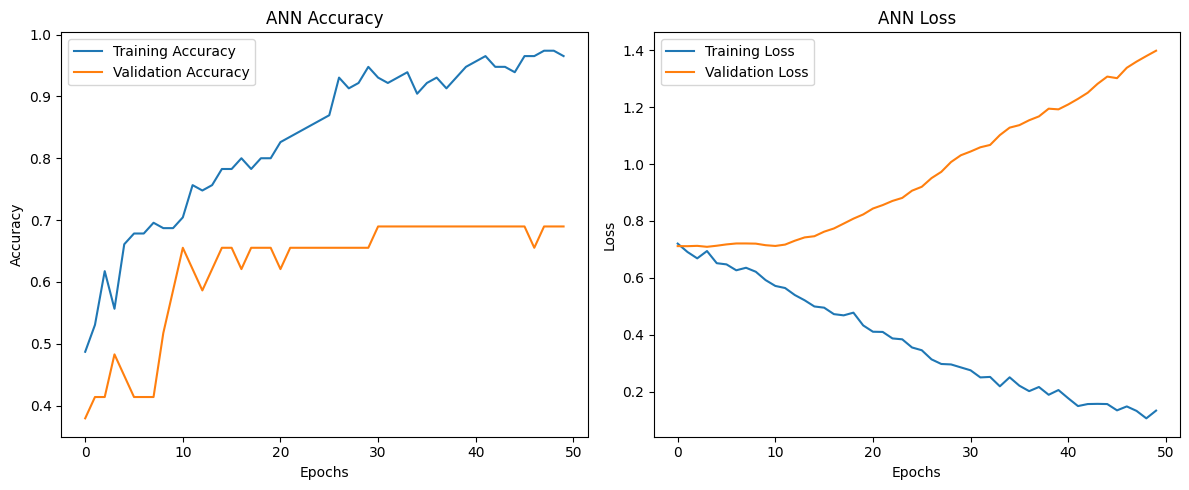

In [23]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_ann.history['accuracy'], label='Training Accuracy')
plt.plot(history_ann.history['val_accuracy'], label='Validation Accuracy')
plt.title('ANN Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_ann.history['loss'], label='Training Loss')
plt.plot(history_ann.history['val_loss'], label='Validation Loss')
plt.title('ANN Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [24]:
from tensorflow.keras.callbacks import EarlyStopping

model_ann = Sequential([
    Dense(32, activation='relu', input_shape=(18,)),
    Dropout(0.3),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

model_ann.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True
)

history_ann = model_ann.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.4696 - loss: 0.7691 - val_accuracy: 0.4828 - val_loss: 0.7324
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5652 - loss: 0.7269 - val_accuracy: 0.4828 - val_loss: 0.7198
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5391 - loss: 0.7481 - val_accuracy: 0.5517 - val_loss: 0.7079
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4870 - loss: 0.7477 - val_accuracy: 0.5517 - val_loss: 0.7005
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4609 - loss: 0.7315 - val_accuracy: 0.5172 - val_loss: 0.6957
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5739 - loss: 0.6442 - val_accuracy: 0.5862 - val_loss: 0.6846
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5739 - loss: 0.6688 - val_accuracy: 0.6207 - val_loss: 0.6782
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5652 - loss: 0.6682 - val_accuracy: 0.6207 - val_loss:

In [25]:
test_loss, test_accuracy = model_ann.evaluate(X_test, y_test)

print("ANN Test Loss:", test_loss)
print("ANN Test Accuracy:", test_accuracy * 100, "%")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.6389 - loss: 0.6854
ANN Test Loss: 0.6854106783866882
ANN Test Accuracy: 63.88888955116272 %


In [26]:
y_pred_prob = model_ann.predict(X_test)

y_pred_ann = (y_pred_prob > 0.5).astype(int).ravel()

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


In [27]:
print(classification_report(y_test, y_pred_ann))

              precision    recall  f1-score   support

           0       0.60      0.71      0.65        17
           1       0.69      0.58      0.63        19

    accuracy                           0.64        36
   macro avg       0.64      0.64      0.64        36
weighted avg       0.65      0.64      0.64        36



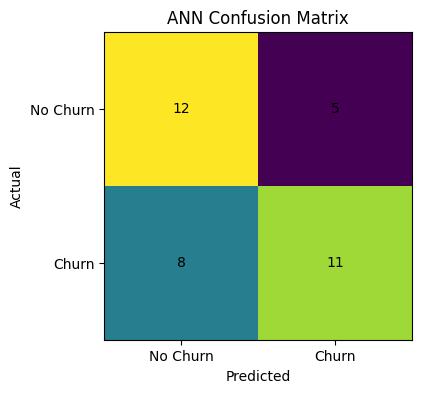

In [28]:
cm = confusion_matrix(y_test, y_pred_ann)

plt.figure(figsize=(6, 4))
plt.imshow(cm)

plt.title("ANN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0, 1], ['No Churn', 'Churn'])
plt.yticks([0, 1], ['No Churn', 'Churn'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.show()

## Reccurent Neural Network(RNN)

## Reshaping Data for RNN

RNN models require 3-dimensional input data.

The data is reshaped into the format:
(samples, timesteps, features).

Each customer is represented as one timestep containing
18 input features.

In [29]:
X_train_rnn = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)

X_test_rnn = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

In [30]:
print("RNN Training Shape:", X_train_rnn.shape)

print("RNN Testing Shape:", X_test_rnn.shape)

RNN Training Shape: (144, 18, 1)
RNN Testing Shape: (36, 18, 1)


In [31]:
model_rnn = Sequential()

model_rnn.add(SimpleRNN(64, activation='tanh',
                        input_shape=(18, 1)))

model_rnn.add(Dropout(0.3))

model_rnn.add(Dense(32, activation='relu'))

model_rnn.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [32]:
model_rnn.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,337 (24.75 KB)

 Trainable params: 6,337 (24.75 KB)

 Non-trainable params: 0 (0.00 B)

In [33]:
model_rnn.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [34]:
early_stop_rnn = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True
)

history_rnn = model_rnn.fit(
    X_train_rnn,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stop_rnn],
    verbose=1
)

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - accuracy: 0.5130 - loss: 0.7002 - val_accuracy: 0.6207 - val_loss: 0.7018
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6696 - loss: 0.6401 - val_accuracy: 0.6207 - val_loss: 0.6959
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6957 - loss: 0.6204 - val_accuracy: 0.6207 - val_loss: 0.6853
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6783 - loss: 0.6179 - val_accuracy: 0.6207 - val_loss: 0.6783
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7304 - loss: 0.5766 - val_accuracy: 0.6552 - val_loss: 0.6769
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6435 - loss: 0.5987 - val_accuracy: 0.6552 - val_loss: 0.6909
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6957 - loss: 0.5582 - val_accuracy: 0.6552 - val_loss: 0.7165
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7304 - loss: 0.5573 - val_accuracy: 0.6552 - val_loss:

In [35]:
rnn_loss, rnn_accuracy = model_rnn.evaluate(
    X_test_rnn, y_test
)

print("RNN Test Loss:", rnn_loss)

print("RNN Test Accuracy:", rnn_accuracy * 100, "%")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.5833 - loss: 0.6939
RNN Test Loss: 0.6938573718070984
RNN Test Accuracy: 58.33333134651184 %


In [36]:
y_pred_rnn_prob = model_rnn.predict(X_test_rnn)

y_pred_rnn = (y_pred_rnn_prob > 0.5).astype(int).ravel()

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step


In [37]:
print(classification_report(y_test, y_pred_rnn))

              precision    recall  f1-score   support

           0       0.55      0.71      0.62        17
           1       0.64      0.47      0.55        19

    accuracy                           0.58        36
   macro avg       0.59      0.59      0.58        36
weighted avg       0.60      0.58      0.58        36



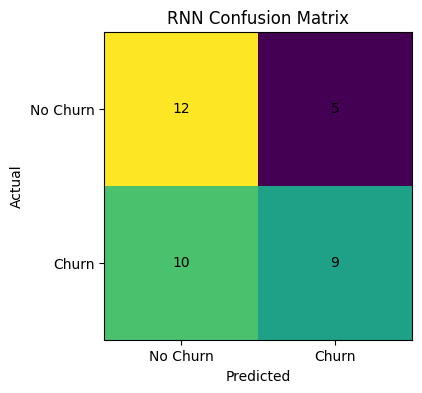

In [38]:
cm_rnn = confusion_matrix(y_test, y_pred_rnn)

plt.figure(figsize=(6, 4))

plt.imshow(cm_rnn)

plt.title("RNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ['No Churn', 'Churn'])
plt.yticks([0, 1], ['No Churn', 'Churn'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm_rnn[i, j], ha='center', va='center')

plt.show()

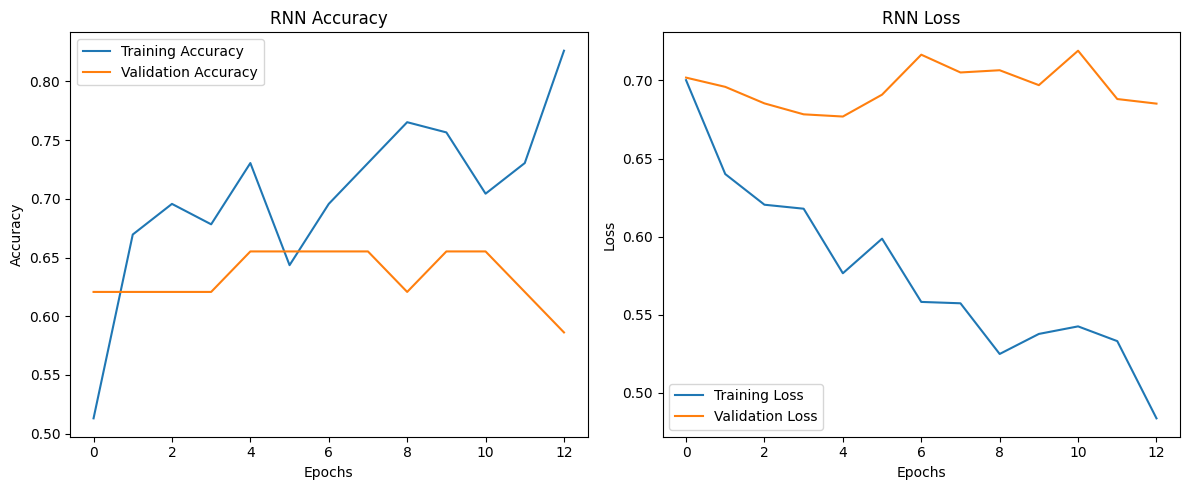

In [39]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_rnn.history['accuracy'], label='Training Accuracy')
plt.plot(history_rnn.history['val_accuracy'], label='Validation Accuracy')
plt.title('RNN Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_rnn.history['loss'], label='Training Loss')
plt.plot(history_rnn.history['val_loss'], label='Validation Loss')
plt.title('RNN Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

##Building LSTM Model

## Reshaping Data for LSTM

LSTM requires 3-dimensional input data containing
samples, timesteps, and features.

The customer data is reshaped into the required format.

In [40]:
X_train_lstm = X_train.reshape(X_train.shape[0], 1, X_train.shape[1])

X_test_lstm = X_test.reshape(X_test.shape[0], 1, X_test.shape[1])

In [41]:
print("LSTM Training Shape:", X_train_lstm.shape)

print("LSTM Testing Shape:", X_test_lstm.shape)

LSTM Training Shape: (144, 1, 18)
LSTM Testing Shape: (36, 1, 18)


In [42]:
model_lstm = Sequential()

model_lstm.add(LSTM(
    64,
    activation='tanh',
    input_shape=(1, 18)
))

model_lstm.add(Dropout(0.3))

model_lstm.add(Dense(32, activation='relu'))

model_lstm.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [43]:
model_lstm.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        21,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,361 (91.25 KB)

 Trainable params: 23,361 (91.25 KB)

 Non-trainable params: 0 (0.00 B)

In [44]:
model_lstm.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [45]:
early_stop_lstm = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True
)

history_lstm = model_lstm.fit(
    X_train_lstm,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stop_lstm],
    verbose=1
)

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step - accuracy: 0.5217 - loss: 0.6936 - val_accuracy: 0.4138 - val_loss: 0.6989
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5217 - loss: 0.6861 - val_accuracy: 0.4483 - val_loss: 0.6926
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6000 - loss: 0.6759 - val_accuracy: 0.4828 - val_loss: 0.6851
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6261 - loss: 0.6725 - val_accuracy: 0.5517 - val_loss: 0.6775
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7043 - loss: 0.6608 - val_accuracy: 0.5862 - val_loss: 0.6714
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6696 - loss: 0.6594 - val_accuracy: 0.6207 - val_loss: 0.6632
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.6783 - loss: 0.6445 - val_accuracy: 0.6207 - val_loss: 0.6558
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.7043 - loss: 0.6479 - val_accuracy: 0.5862 - val_loss:

In [46]:
lstm_loss, lstm_accuracy = model_lstm.evaluate(
    X_test_lstm, y_test
)

print("LSTM Test Loss:", lstm_loss)

print("LSTM Test Accuracy:", lstm_accuracy * 100, "%")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.5556 - loss: 0.6729
LSTM Test Loss: 0.672934353351593
LSTM Test Accuracy: 55.55555820465088 %


In [47]:
y_pred_lstm_prob = model_lstm.predict(X_test_lstm)

y_pred_lstm = (y_pred_lstm_prob > 0.5).astype(int).ravel()

1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step


In [48]:
print(classification_report(y_test, y_pred_lstm))

              precision    recall  f1-score   support

           0       0.52      0.65      0.58        17
           1       0.60      0.47      0.53        19

    accuracy                           0.56        36
   macro avg       0.56      0.56      0.55        36
weighted avg       0.56      0.56      0.55        36



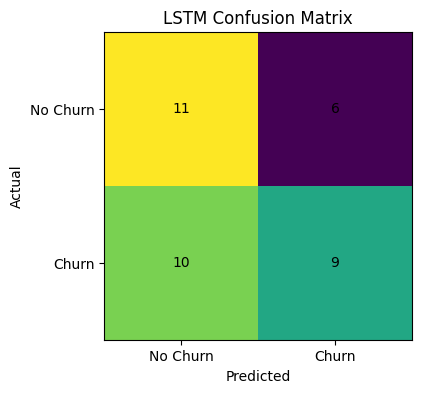

In [49]:
cm_lstm = confusion_matrix(y_test, y_pred_lstm)

plt.figure(figsize=(6, 4))

plt.imshow(cm_lstm)

plt.title("LSTM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ['No Churn', 'Churn'])
plt.yticks([0, 1], ['No Churn', 'Churn'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm_lstm[i, j], ha='center', va='center')

plt.show()

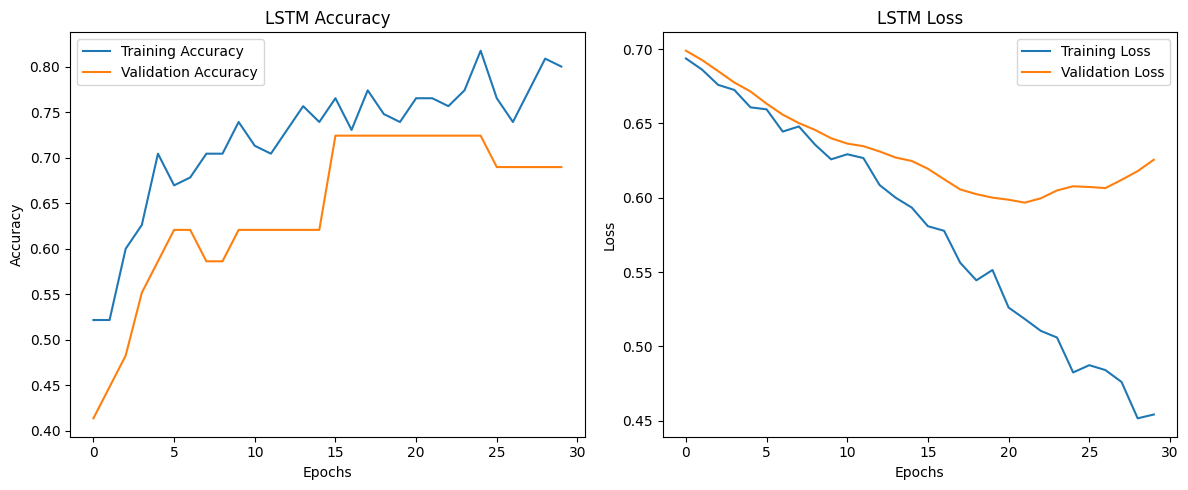

In [50]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_lstm.history['accuracy'], label='Training Accuracy')
plt.plot(history_lstm.history['val_accuracy'], label='Validation Accuracy')
plt.title('LSTM Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_lstm.history['loss'], label='Training Loss')
plt.plot(history_lstm.history['val_loss'], label='Validation Loss')
plt.title('LSTM Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [51]:
comparison = pd.DataFrame({
    'Model': ['ANN', 'RNN', 'LSTM'],
    'Test Accuracy': [
        test_accuracy * 100,
        rnn_accuracy * 100,
        lstm_accuracy * 100
    ],
    'Test Loss': [
        test_loss,
        rnn_loss,
        lstm_loss
    ]
})

comparison

,Model,Test Accuracy,Test Loss
0,ANN,63.888890,0.685411
1,RNN,58.333331,0.693857
2,LSTM,55.555558,0.672934


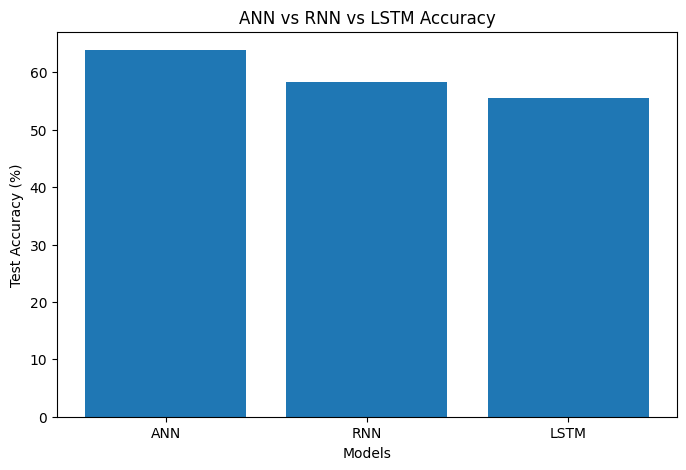

In [52]:
plt.figure(figsize=(8, 5))

plt.bar(comparison['Model'], comparison['Test Accuracy'])

plt.title('ANN vs RNN vs LSTM Accuracy')
plt.xlabel('Models')
plt.ylabel('Test Accuracy (%)')

plt.show()